In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mathyn

In [ ]:
def f(x): return x**2 + 2
dx = 0.1
x = np.arange(-np.pi, np.pi, dx)
x1 = np.arange(-np.pi / 2, np.pi / 2, dx)

In [67]:
md = mathyn.differentiation
y = f(x)
d1ydx = md.derivative(f, dx)
d2ydx = md.derivative(d1ydx, dx)
d3ydx = md.derivative(d2ydx, dx)
dy1 = d1ydx(x)
dy2 = d2ydx(x)
dy3 = d3ydx(x)

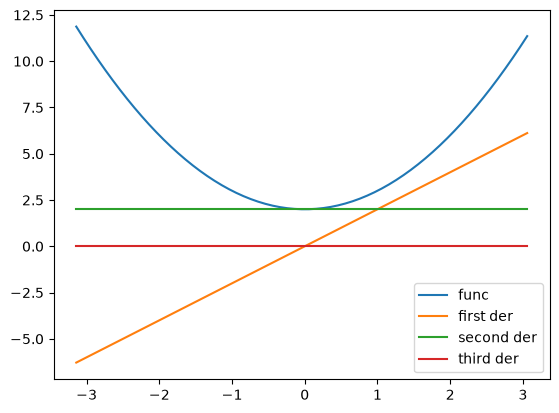

In [68]:
plt.figure()
plt.plot(x, y)
plt.plot(x, dy1)
plt.plot(x, dy2)
plt.plot(x, dy3)
plt.legend(["func","first der", "second der", "third der"])
plt.show()

In [106]:
a = 1
tangent_line = mathyn.vector_calculus.tangent_line_of_curve(f, a, dx)
yt = tangent_line(x)
normal_line = mathyn.vector_calculus.normal_line_of_curve(f,a,dx)
yn = normal_line(x)

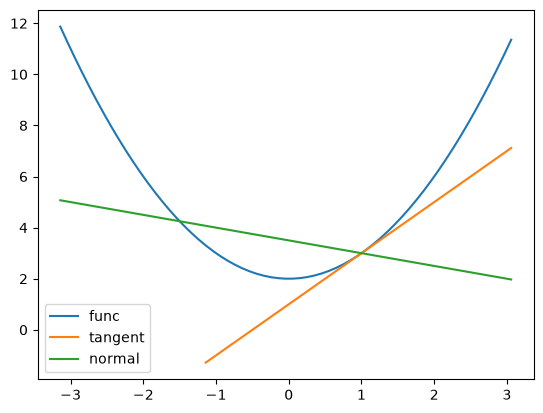

In [107]:
plt.figure()
plt.plot(x, y)
plt.plot(x[20:], yt[20:])
plt.plot(x, yn)
plt.legend(["func", "tangent", "normal"])
plt.show()

In [108]:
def left_point_rule(f, a, b, n):
    h = (b - a) / n
    x = np.arange(a, b, h)
    y = f(x)
    s = y.sum() * h
    return s


def right_point_rule(f, a, b, n):
    h = (b - a) / n
    x = np.arange(a+h, b+h, h)
    y = f(x)
    s = y.sum() * h
    return s


def mid_point_rule(f, a, b, n):
    h = (b - a) / n
    x = np.arange(a+(h/2), b+(h/2), h)
    y = f(x)
    s = y.sum() * h
    return s


def trapezoidal_rule(f, a, b, n):
    h = (b - a) / n
    x = np.arange(a, b + h, h)
    y = f(x)
    s = h * ((y[0] + y[-1])/2 + y[1:-1].sum())
    return s


def simpsons_rule(f, a, b, n):
    h = (b - a) / (2 * n)
    x = np.arange(a, b + h, h)
    y = f(x)
    even = y[::2]
    odd = y[1::2]
    s = (h / 3) * (y[0] + y[-1] + 2*even[1:-1].sum() + 4*odd.sum())
    return s

In [109]:
a, b = -2, 2
n = 4
h = (b - a) / n

Left-point sum:  14.0


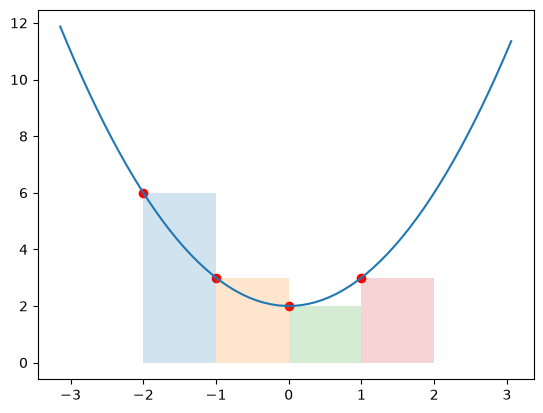

In [110]:
# Left-point sum
s = left_point_rule(f, a, b, n)
xp = np.arange(a, b, h)
yp = f(xp)
plt.plot(x, y)
plt.scatter(xp, yp, c="r")
plt.fill_between(xp[:2],[yp[0], yp[0]], alpha=0.2)
plt.fill_between(xp[1:3],[yp[1], yp[1]], alpha=0.2)
plt.fill_between(xp[2:4],[yp[2], yp[2]], alpha=0.2)
plt.fill_between([xp[-1],xp[-1] + h],[yp[-1], yp[-1]], alpha=0.2)
print("Left-point sum: ", s)

Right-point sum:  14.0


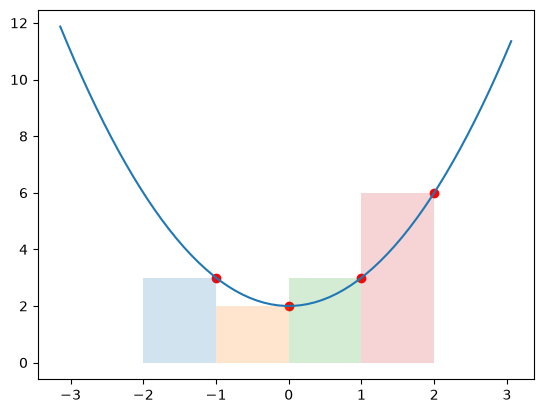

In [111]:
# Right-point sum
s = right_point_rule(f, a, b, n)
xp = np.arange(a+h, b+h, h)
yp = f(xp)
plt.plot(x, y)
plt.scatter(xp, yp, c="r")
plt.fill_between([xp[0]-h,xp[0]],[yp[0], yp[0]], alpha=0.2)
plt.fill_between(xp[:2],[yp[1], yp[1]], alpha=0.2)
plt.fill_between(xp[1:3],[yp[2], yp[2]], alpha=0.2)
plt.fill_between(xp[2:],[yp[3], yp[3]], alpha=0.2)
print("Right-point sum: ", s)

Mid-point sum:  13.0


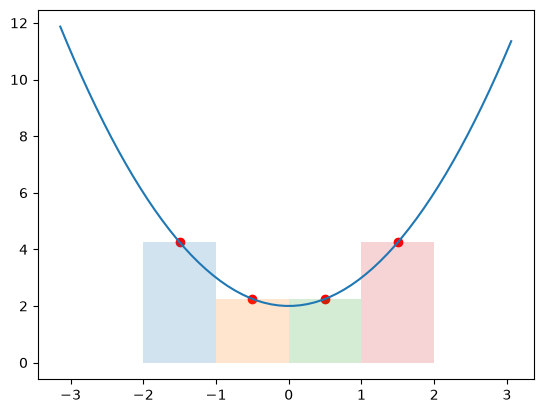

In [112]:
# Mid-point sum
s = mid_point_rule(f, a, b, n)
xp = np.arange(a, b, h)
xpc = np.arange(a+(h/2), b+(h/2), h)
yp = f(xpc)
plt.plot(x, y)
plt.scatter(xpc, yp, c="r")
plt.fill_between(xp[:2],[yp[0], yp[0]], alpha=0.2)
plt.fill_between(xp[1:3],[yp[1], yp[1]], alpha=0.2)
plt.fill_between(xp[2:4],[yp[2], yp[2]], alpha=0.2)
plt.fill_between([xp[-1],xp[-1] + h],[yp[-1], yp[-1]], alpha=0.2)
print("Mid-point sum: ", s)

Trapezoidal rule:  14.0


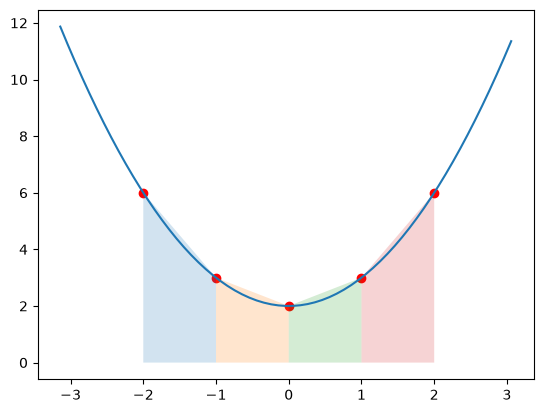

In [113]:
# Trapezoidal rule
s = trapezoidal_rule(f, a, b, n)
xp = np.arange(a, b + h, h)
yp = f(xp)
plt.plot(x, y)
plt.scatter(xp, yp, c="r")
plt.fill_between(xp[:2],yp[:2], alpha=0.2)
plt.fill_between(xp[1:3],yp[1:3], alpha=0.2)
plt.fill_between(xp[2:4],yp[2:4], alpha=0.2)
plt.fill_between(xp[3:],yp[3:], alpha=0.2)
print("Trapezoidal rule: ", s)

Simpson's rule:  13.333333333333332


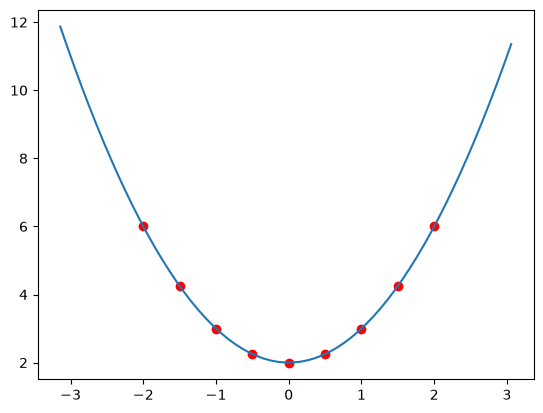

In [114]:
# Simpson's rule
s = simpsons_rule(f, a, b, n)
h = (b - a) / (2 * n)
xp = np.arange(a, b + h, h)
yp = f(xp)
plt.plot(x, y)
plt.scatter(xp, yp, c="r")
print("Simpson's rule: ", s)